# Your own initial conditions, run through `luna.launch`

LUNA's registered problems (`test_problem`, `luna/ic_generation/ic.py`) fix their initial states;
their numbers are set through `problem=<module>.Params(...)` or `problem.<name>=value`. A state of
your own goes straight to `launch`, in the run's own dimension (1D, 2D or 3D), as the conserved
variables with energy last, `(rho, rho vx, [rho vy, [rho vz,]] E)`:

- `launch(cfg, ic=f)`: `f(x, y, z, cfg)` gets the cell centres of the cells it is to fill (x = (i + 1/2)
  Lx / Nx from 0; arrays of the cells' shape, `y`, `z` None below their dimension) and returns
  their state, `(4, nx, ny)` in 2D. On several devices or processes each process calls it for its
  own part of the grid only, so this route scales to any grid.
- `launch(cfg, U0=U)`: the whole grid as one array, `(3, Nx)`, `(4, Nx, Ny)` or `(5, Nx, Ny, Nz)`.

A shape that does not fit the config (a 3D array for a 2D run, one cell too many) is refused,
naming the shape it needs. `luna.conserved(rho, (vx, vy), p, gamma)` turns primitives into that
state. Either takes the path `python main.py` takes (`luna/ic_generation/user_ic.py`);
`test_problem` then only names the run. How to register a problem in the library instead is in
[docs/ADDING_A_PROBLEM.md](../../docs/ADDING_A_PROBLEM.md).

The example: a hot spot (pressure 100 times the ambient) next to a cloud 10 times denser than its
surroundings, in a periodic 2D box at 256², gamma = 5/3, HLLC, minmod, FP64. The blast wave reaches
the cloud by the end (t = 0.08). There is no reference solution: the one check is that mass, energy and
momentum in the periodic box stay at their initial values to round-off.

Runtime: about 15 seconds on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg, **state):
    """launch(cfg, **state), as `python main.py` runs it (state: U0= or ic=, an initial state of our own),
    with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg, **state)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

Define the initial state as a function of position, in primitive variables, and return the
conserved state `(rho, rho vx, rho vy, E)` of the cells it is handed.

In [2]:
from luna import conserved

N, GAMMA, T_END = 256, 5.0 / 3.0, 0.08


def smooth_step(r, r0, w=0.01):
    """1 inside r0, 0 outside, over a few cells (a smooth edge keeps the start clean)."""
    return 0.5 * (1.0 - np.tanh((r - r0) / w))


def hot_spot_and_cloud(x, y, z, cfg):
    """(rho, rho vx, rho vy, E) on the cells with centres x, y (z is None in 2D)."""
    rho = 1.0 + 9.0 * smooth_step(np.hypot(x - 0.6, y - 0.5), 0.1)        # the cloud
    p = 1.0 + 99.0 * smooth_step(np.hypot(x - 0.3, y - 0.5), 0.04)        # the hot spot
    return conserved(rho, (0.0, 0.0), p, cfg.gamma)                        # at rest

Run it: a 2D config (`SPATIAL_DIMENSION=2`, `Nx`, `Ny`), and the function as `ic=`.

In [3]:
cfg = replace(BASE, test_problem="Hot-Spot-And-Cloud", SPATIAL_DIMENSION=2, Nx=N, Ny=N,
              Lx=1.0, Ly=1.0, BOUNDARY=0, gamma=GAMMA, t_end=T_END,
              time_bet_snaps=T_END / 4, output_dir="snapshots/nb12/run")
res, wall = run(cfg, ic=hot_spot_and_cloud)
print(f"t = {res.t:.3f}, {res.n_steps} steps, {wall:.1f} s")

t = 0.080, 373 steps, 9.1 s


mass: relative change 0.0e+00
energy: relative change 4.4e-16
momentum x, y: 5.4e-18, 8.5e-19 (of the mass, initially 0)


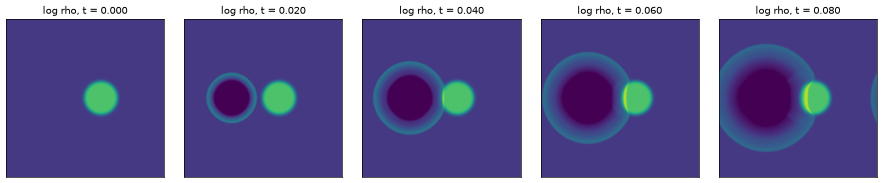

In [4]:
import glob
from luna.file_io.read_snapshot import read_snapshot

snaps = [read_snapshot(d) for d in sorted(glob.glob(f"{cfg.output_dir}/snapdir_*"))]
fig, ax = plt.subplots(1, len(snaps), figsize=(3 * len(snaps), 3), dpi=60)
for a, s in zip(ax, snaps):
    a.imshow(np.log10(s["rho"].T), origin="lower", extent=(0, 1, 0, 1), cmap="viridis", vmin=-0.3, vmax=1.5)
    a.set_title(f"log rho, t = {s['t']:.3f}"); a.set_xticks([]); a.set_yticks([])
fig.tight_layout()

x = (np.arange(N) + 0.5) / N
U0 = hot_spot_and_cloud(*np.meshgrid(x, x, indexing="ij"), None, cfg)   # the whole initial grid
U = np.asarray(res.extra["U"], np.float64)
for name, i in (("mass", 0), ("energy", 3)):
    print(f"{name}: relative change {abs(U[i].sum() / U0[i].sum() - 1):.1e}")
print(f"momentum x, y: {abs(U[1].sum()) / U0[0].sum():.1e}, {abs(U[2].sum()) / U0[0].sum():.1e} (of the mass, initially 0)")

**What this shows.** Mass and energy stay at their initial values to 4e-16 and the total momentum at 1e-17 of the mass: the conservation the finite-volume scheme guarantees in a periodic box. Nothing else is checked.

This is a demonstration of the input route, not a validation: the solver's validated cases and
their tests are listed in `docs/CLAIMS.md` (notebooks 03-11 rerun several of them).